# IntroStat Week 11

Welcome to the 11th lecture in IntroStat

During the lectures we will present both slides and notebooks. 

This is the notebook used in the lecture in week 11.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.power as smp
import statsmodels.stats.proportion as smprop

## One-way ANOVA: Agricultural Analogy - Crop Yield Experiment

### Scenario:
Imagine a farmer wants to test the effectiveness of three different fertilizer types (Organic, Chemical, and Balanced) on corn yield across multiple test plots.

### Experimental Setup:

3 fertilizers <br>
5 plots per fertilizer type <br>
Measure corn yield in bushels per acre

### *Block* Analogy Explanation:

Think of ANOVA like applying **treatment** fertilizers in into different "**blocks**" of fields.<br>
We want to know **if the fertilizer or treatment significantly impacts crop yield from the blocks**<br>
There can be variation WITHIN each fertilizer or *treatment* groups vs. variation BETWEEN fertilizer or *treatment* groups

### Null Hypothesis ($H_0$):
  $
    \mu_1 = \mu_2 = \mu_3
    $
- The mean corn yields are equal across all three fertilizer types.
- There is no significant difference in crop yield between the Organic, Chemical, and Balanced fertilizers.

### Alternative Hypothesis ($H_1$):
$
  \text{At least one } \mu \text{ differs}
  $
- At least one fertilizer type has a significantly different mean yield.
- Not all fertilizer group means are the same.

### Symbolic Representation:
$  H_0: \mu_\text{Organic} = \mu_\text{Chemical} = \mu_\text{Balanced}$ <br>
$H_1: \text{At least one } \mu \text{ is different from the others.}$

### Decision Rule:
- Reject $H_0$ if $p < 0.05$: Fertilizer types significantly differ in mean yield.
- Fail to reject $H_0$ if $p \geq 0.05$: No significant evidence of differences in mean yield.

In [2]:
import scipy.stats as stats
import numpy as np

# Corn yield data (bushels per acre)
organic_yield = [45, 47, 44, 46, 48]
chemical_yield = [52, 55, 53, 54, 51]
balanced_yield = [49, 50, 48, 51, 50]

# Combine data
all_yields = [organic_yield, chemical_yield, balanced_yield]

# Perform one-way ANOVA
f_statistic, p_value = stats.f_oneway(organic_yield, chemical_yield, balanced_yield)

print("ANOVA Results:")
print(f"F-statistic: {f_statistic}")
print(f"P-value: {p_value}")

# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Fertilizer types as treatements significantly differ the crop yield. So, at least one mean is differnt from others")
else:
    print("No significant difference between fertilizer types")

ANOVA Results:
F-statistic: 29.174603174603178
P-value: 2.463384830329642e-05
Fertilizer types as treatements significantly differ the crop yield. So, at least one mean is differnt from others


### Example: Intro to ANOVA

Is there a difference (in mean) between groups A, B, and C?
Analysis of variance (ANOVA) can be used for the analysis, <br>
provided **the observations in each group can be assumed to be normally distributed.**

| Group A | Group B | Group C |
|---------|---------|---------|
| 2.8     | 5.5     | 5.8     |
| 3.6     | 6.3     | 8.3     |
| 3.4     | 6.1     | 6.9     |
| 2.3     | 5.7     | 6.1     |


In [3]:
# Make pandas dataframe with grouped data:
data = pd.DataFrame({
    'value':  [2.8, 3.6, 3.4, 2.3, 5.5, 6.3, 6.1, 5.7, 5.8, 8.3, 6.9, 6.1], 
    'group':  ["A", "A", "A", "A", "B", "B", "B", "B", "C", "C", "C", "C"]})
data

,value,group
0,2.8,A
1,3.6,A
2,3.4,A
3,2.3,A
4,5.5,B
5,6.3,B
6,6.1,B
7,5.7,B
8,5.8,C
9,8.3,C


<Axes: xlabel='group', ylabel='value'>

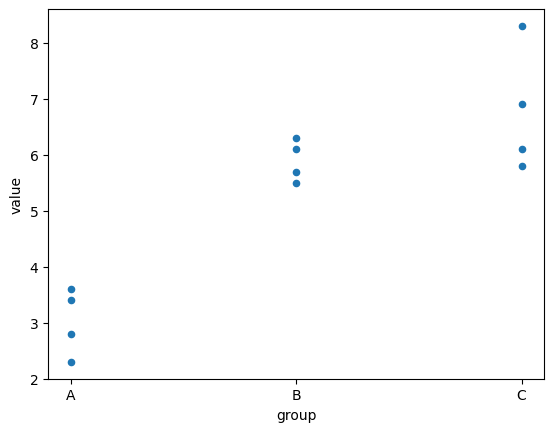

In [4]:
data.plot.scatter('group', 'value') # Pandas scatter plot

<Axes: title={'center': 'value'}, xlabel='[group]'>

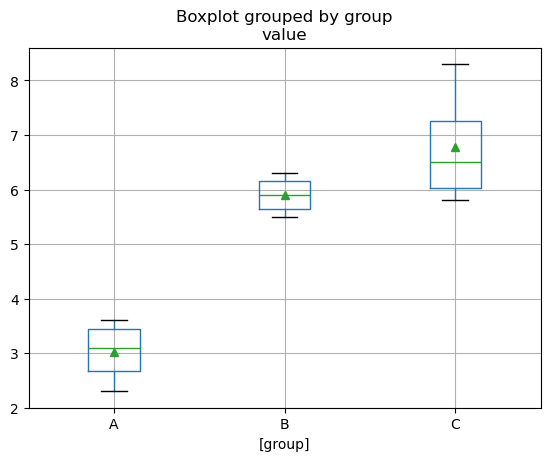

In [5]:
data.boxplot(by="group", showmeans=True) # Pandas boxplot

The three groups have different means - indicated by the green triangles

<Axes: >

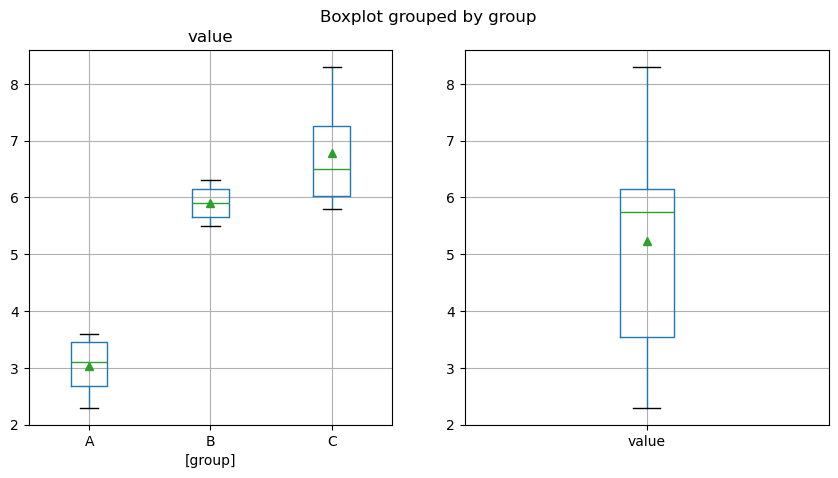

In [6]:
# compare visualising the three groups seperately versus all data pooled together:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
data.boxplot(by="group", ax=axs[0], showmeans=True)
data.boxplot(ax=axs[1], showmeans=True)

Questions:

Do you think there is a significant difference between the groups? (why? or why not? and what would make the difference more clear/more significant?)

Do you think the data in the three groups could each be a random subset of the pooled data?

C:\Users\skhalid\AppData\Local\Temp\ipykernel_21020\2609512737.py:6: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  data.boxplot(by="random", ax=axs[0], showmeans=True)


<Axes: >

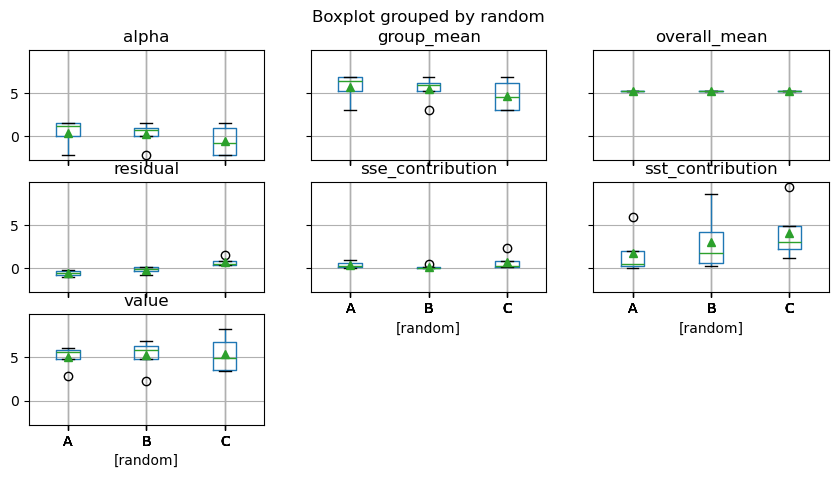

In [31]:
# lets make a random allocation of group and plot again (run this cell several times to simulate new random groups)
data["random"] = np.random.choice(data["group"], replace=False, size=len(data))

# compare visualising the three groups seperately versus all data pooled together:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
data.boxplot(by="random", ax=axs[0], showmeans=True)
data.boxplot(ax=axs[1], showmeans=True)


### Example: Estimate parameters $\mu$, $\alpha_i$ and $\sigma^2$

In [8]:
# Compute the overall mean and add to dataframe:
data['overall_mean'] = data["value"].mean()
data

,value,group,random,overall_mean
0,2.8,A,B,5.233333
1,3.6,A,B,5.233333
2,3.4,A,C,5.233333
3,2.3,A,A,5.233333
4,5.5,B,C,5.233333
5,6.3,B,B,5.233333
6,6.1,B,A,5.233333
7,5.7,B,C,5.233333
8,5.8,C,A,5.233333
9,8.3,C,C,5.233333


In [9]:
# compute the mean within each group and add to dataframe:
data['group_mean'] = data.groupby("group")['value'].transform('mean')
data

,value,group,random,overall_mean,group_mean
0,2.8,A,B,5.233333,3.025
1,3.6,A,B,5.233333,3.025
2,3.4,A,C,5.233333,3.025
3,2.3,A,A,5.233333,3.025
4,5.5,B,C,5.233333,5.900
5,6.3,B,B,5.233333,5.900
6,6.1,B,A,5.233333,5.900
7,5.7,B,C,5.233333,5.900
8,5.8,C,A,5.233333,6.775
9,8.3,C,C,5.233333,6.775


In [10]:
# compute the "alpha" for each group and add to dataframe:
data["alpha"] = data["group_mean"] - data["overall_mean"]
data

,value,group,random,overall_mean,group_mean,alpha
0,2.8,A,B,5.233333,3.025,-2.208333
1,3.6,A,B,5.233333,3.025,-2.208333
2,3.4,A,C,5.233333,3.025,-2.208333
3,2.3,A,A,5.233333,3.025,-2.208333
4,5.5,B,C,5.233333,5.900,0.666667
5,6.3,B,B,5.233333,5.900,0.666667
6,6.1,B,A,5.233333,5.900,0.666667
7,5.7,B,C,5.233333,5.900,0.666667
8,5.8,C,A,5.233333,6.775,1.541667
9,8.3,C,C,5.233333,6.775,1.541667


### Variation within groups (Residual variation left after the model):

$
SSE = \sum_{i=1}^{k} \sum_{j=1}^{n_i} \left( y_{ij} - \bar{y}_i \right)^2
$

In [11]:
# calculate the individual contribution to SSE and add to dataframe:
data['sse_contribution'] = (data['value']-data['group_mean'])**2
data

,value,group,random,overall_mean,group_mean,alpha,sse_contribution
0,2.8,A,B,5.233333,3.025,-2.208333,0.050625
1,3.6,A,B,5.233333,3.025,-2.208333,0.330625
2,3.4,A,C,5.233333,3.025,-2.208333,0.140625
3,2.3,A,A,5.233333,3.025,-2.208333,0.525625
4,5.5,B,C,5.233333,5.900,0.666667,0.160000
5,6.3,B,B,5.233333,5.900,0.666667,0.160000
6,6.1,B,A,5.233333,5.900,0.666667,0.040000
7,5.7,B,C,5.233333,5.900,0.666667,0.040000
8,5.8,C,A,5.233333,6.775,1.541667,0.950625
9,8.3,C,C,5.233333,6.775,1.541667,2.325625




$
\hat{\sigma}^2 = MSE = \frac{SSE}{n-k}
$

In [12]:
# calculate SSE and MSE:
SSE = data["sse_contribution"].sum()
MSE = SSE / (12-3)
print([SSE, MSE])

[5.195000000000004, 0.5772222222222226]


### Example: ANOVA table with python

In [13]:
# Make the ANOVA table:
fit = smf.ols("value ~ group", data=data).fit()
anova_table = sm.stats.anova_lm(fit)
print(anova_table)


           df     sum_sq    mean_sq          F    PR(>F)
group     2.0  30.791667  15.395833  26.672281  0.000165
Residual  9.0   5.195000   0.577222        NaN       NaN


### Example: F-test

OBS: The F-test is also part of the ANOVA table output (see table above)

Here we also do the calculation *manually*

In [14]:
# We have already calculated SSE and MSE
print([SSE, MSE])

[5.195000000000004, 0.5772222222222226]


In [15]:
# recall the data:
data

,value,group,random,overall_mean,group_mean,alpha,sse_contribution
0,2.8,A,B,5.233333,3.025,-2.208333,0.050625
1,3.6,A,B,5.233333,3.025,-2.208333,0.330625
2,3.4,A,C,5.233333,3.025,-2.208333,0.140625
3,2.3,A,A,5.233333,3.025,-2.208333,0.525625
4,5.5,B,C,5.233333,5.900,0.666667,0.160000
5,6.3,B,B,5.233333,5.900,0.666667,0.160000
6,6.1,B,A,5.233333,5.900,0.666667,0.040000
7,5.7,B,C,5.233333,5.900,0.666667,0.040000
8,5.8,C,A,5.233333,6.775,1.541667,0.950625
9,8.3,C,C,5.233333,6.775,1.541667,2.325625


In [16]:
# calculate SST contribution of each datapoint:
data["sst_contribution"] = (data["value"] - data["overall_mean"])**2
data

,value,group,random,overall_mean,group_mean,alpha,sse_contribution,sst_contribution
0,2.8,A,B,5.233333,3.025,-2.208333,0.050625,5.921111
1,3.6,A,B,5.233333,3.025,-2.208333,0.330625,2.667778
2,3.4,A,C,5.233333,3.025,-2.208333,0.140625,3.361111
3,2.3,A,A,5.233333,3.025,-2.208333,0.525625,8.604444
4,5.5,B,C,5.233333,5.900,0.666667,0.160000,0.071111
5,6.3,B,B,5.233333,5.900,0.666667,0.160000,1.137778
6,6.1,B,A,5.233333,5.900,0.666667,0.040000,0.751111
7,5.7,B,C,5.233333,5.900,0.666667,0.040000,0.217778
8,5.8,C,A,5.233333,6.775,1.541667,0.950625,0.321111
9,8.3,C,C,5.233333,6.775,1.541667,2.325625,9.404444


In [17]:
# calculate SST:
SST = data["sst_contribution"].sum()
print([SST])

[35.98666666666667]


In [18]:
# We know SST = SSTr + SSE
# Calculate SSTr and MSTr:
SSTr = SST - SSE
MSTr = SSTr / (3-1)
print([SSTr, MSTr])

[30.791666666666668, 15.395833333333334]


In [19]:
# Now we can calculate the test-statistic F = MSTr / MSE
Fobs = MSTr / MSE
print(Fobs)

26.672281039461


In [20]:
# compare with critical value
print(stats.f.ppf(0.95, dfn = 3-1, dfd = 12-3))

# dfn: Degrees of freedom for the numerator (the between-groups variability, often 𝑘−1 , 
# where 𝑘 is the number of groups.
# dfd: Degrees of freedom for the denominator (the within-groups variability, often 𝑁−𝑘, 
# where N is the total number of observations, and k is the number of groups).

4.25649472909375


In [21]:
# From Fobs we get a p-value:
pvalue = 1 - stats.f.cdf(Fobs, dfn = 3-1, dfd = 12-3)
print(pvalue)

0.0001650052218172826


In [22]:
# compare with values in ANOVA table:
print(anova_table)

           df     sum_sq    mean_sq          F    PR(>F)
group     2.0  30.791667  15.395833  26.672281  0.000165
Residual  9.0   5.195000   0.577222        NaN       NaN


KAHOOT (5-8)

### Example: Model control

The assumptions for one-way ANOVA model are:
1. The data comes from a normal distribution in each group
2. The variances from each group are the same

The assumptions can be controlled by:
1. The normality within groups assumption: 
   1.  q-q plot within each group but exercise data as low as four observations are not insightful.
   2.  All the residuals for all groups are pooled in a QQ plot, that is, they should all follow the same zero-mean normal distribution.
2.  The homogeneous variances assumption can be controlled by simply looking at the distributions within each sample, most conveniently for this purpose by the group-wise box plot.


<Axes: title={'center': 'value'}, xlabel='group'>

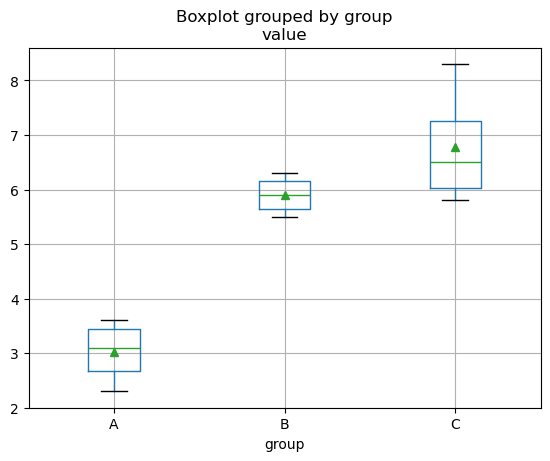

In [23]:
# Visual inspection of equal variance in groups:
data.boxplot("value", by="group", showmeans=True)

In [24]:
# recall how we computed the ANOVA table using Python:
# fit = smf.ols("value ~ group", data=data).fit()
# anova_table = sm.stats.anova_lm(fit)

# from the same "fit" we can get the residuals:
data["residual"] = fit.resid
data

,value,group,random,overall_mean,group_mean,alpha,sse_contribution,sst_contribution,residual
0,2.8,A,B,5.233333,3.025,-2.208333,0.050625,5.921111,-0.225
1,3.6,A,B,5.233333,3.025,-2.208333,0.330625,2.667778,0.575
2,3.4,A,C,5.233333,3.025,-2.208333,0.140625,3.361111,0.375
3,2.3,A,A,5.233333,3.025,-2.208333,0.525625,8.604444,-0.725
4,5.5,B,C,5.233333,5.900,0.666667,0.160000,0.071111,-0.400
5,6.3,B,B,5.233333,5.900,0.666667,0.160000,1.137778,0.400
6,6.1,B,A,5.233333,5.900,0.666667,0.040000,0.751111,0.200
7,5.7,B,C,5.233333,5.900,0.666667,0.040000,0.217778,-0.200
8,5.8,C,A,5.233333,6.775,1.541667,0.950625,0.321111,-0.975
9,8.3,C,C,5.233333,6.775,1.541667,2.325625,9.404444,1.525


OBS: you can check that: 

value = overall_mean + alpha + residual

Lets inspect the residuals behave as we have assumed:

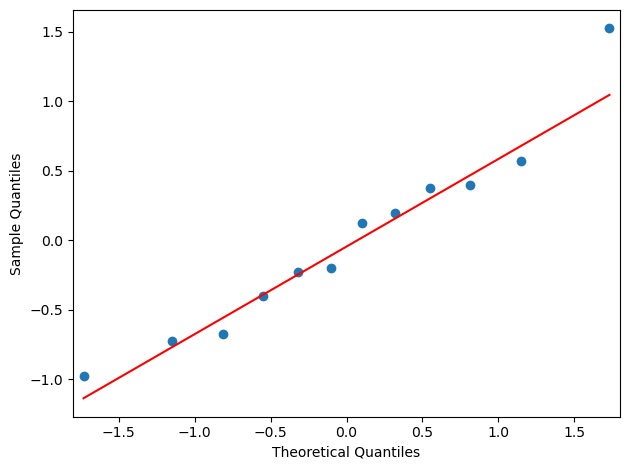

In [25]:
# Assumption about normality (residuals are normally distributed):

# QQplot:
sm.qqplot(data["residual"], line='q',a=1/2)
plt.tight_layout()
plt.show()

<Axes: xlabel='alpha', ylabel='residual'>

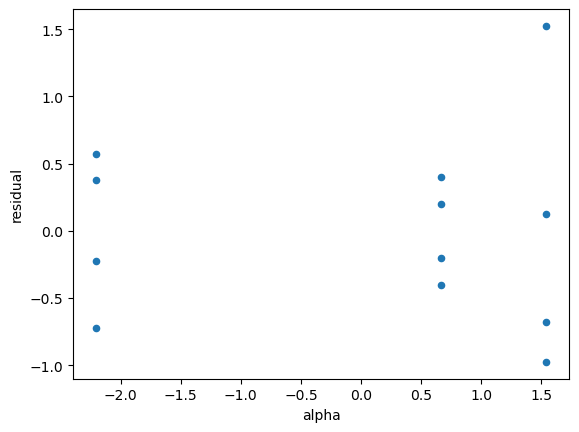

In [26]:
# residuals versus fitted values (overall_mean + alpha)
data.plot.scatter("alpha", "residual")

<Axes: xlabel='group', ylabel='residual'>

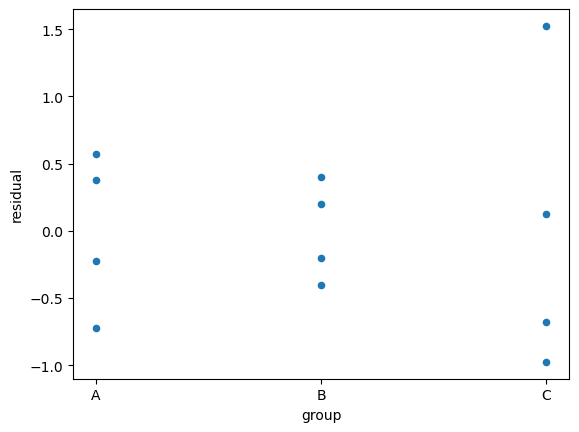

In [27]:
# residual versus group:
data.plot.scatter("group", "residual")

Maybe variance of residuals is a little larger in group C (we reached the same conclusion from looking at original boxplot)

KAHOOT 9

In [ ]:
print(stats.f.ppf(0.95, dfn=2, dfd=15))

3.6823203436732412


In [11]:
Fobs = 13.4957

print(1-stats.f.cdf(Fobs, dfn=2, dfd=15))

0.0004435900391467351


In [ ]:
print(4.106/15)

print(stats.t.ppf(0.95, 15))

0.27373333333333333
1.7530503556925547


In [3]:
import numpy as np
import pandas as pd

nitrogen = np.array([
    5.01, 5.59, 3.02,
    6.23, 5.13, 4.76,
    5.98, 5.33, 3.46,
    5.31, 4.65, 4.12,
    5.13, 5.52, 4.51,
    5.65, 4.92, 4.42,
])

year = pd.Categorical(np.tile(["1998", "2003", "2011"], 6))

D = pd.DataFrame({"nitrogen": nitrogen, "year": year})
print(D)

    nitrogen  year
0       5.01  1998
1       5.59  2003
2       3.02  2011
3       6.23  1998
4       5.13  2003
5       4.76  2011
6       5.98  1998
7       5.33  2003
8       3.46  2011
9       5.31  1998
10      4.65  2003
11      4.12  2011
12      5.13  1998
13      5.52  2003
14      4.51  2011
15      5.65  1998
16      4.92  2003
17      4.42  2011


In [4]:
print(round(17 * D["nitrogen"].var(ddof=1), 3))

11.494


In [5]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

fit = smf.ols("nitrogen ~ year", data=D).fit()
anova = sm.stats.anova_lm(fit)
print(anova)

            df    sum_sq   mean_sq          F    PR(>F)
year       2.0  7.388433  3.694217  13.495787  0.000444
Residual  15.0  4.105967  0.273731        NaN       NaN


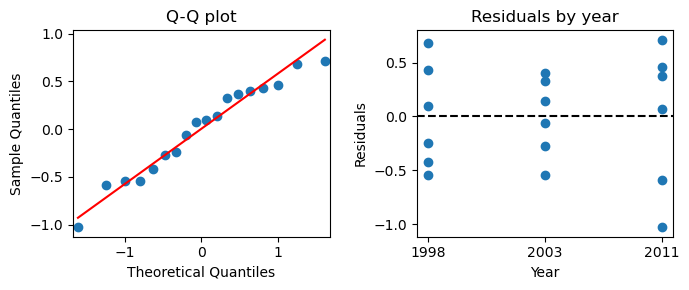

In [6]:
import matplotlib.pyplot as plt

D["residuals"] = fit.resid

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

# Normal Q-Q plot
sm.qqplot(D["residuals"], line="q", ax=axes[0])
axes[0].set_title("Q-Q plot")

# Residuals by year
axes[1].scatter(D["year"], D["residuals"])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals by year")

plt.tight_layout()
plt.show()